In [22]:
import numpy as np
import matplotlib.pyplot as plt
import uproot
import modules.loaddata
import modules.loadroot
import importlib
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, FormatStrFormatter
from scipy.interpolate import interp1d

In [3]:
MeV = 1
GeV = 1000 * MeV
sek = 1 / (6.58211889 * 1E-22 * MeV)
metr = sek / 299792458
meter = metr
millimeter = 0.001 * meter
centimeter = 10 * millimeter
centimeter2 = centimeter ** 2
cm2 = centimeter2
G = 1.16639 * 1E-5 / (GeV * GeV)
m_l = 105.66

In [ ]:
# lfg_data = modules.load
ab_initio_data = modules.loaddata.load_ab_initio("D:\\_\\plugg\\aman26\\fromlinux\\neutrino_bsc_26\\data\\ab_initio_nu_responses\\")
ab_initio_q = ab_initio_data[0]
ab_initio_values = ab_initio_data[1] # Structure: [q, curve, method, value(omega, avg, min, max)]

In [28]:
lfg_data = modules.loaddata.load_response_functions("D:\\_\\plugg\\aman26\\fromlinux\\neutrino_bsc_26\\data\\lfg_week4_data\\", "O16_CC_LFG")

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 3 dimensions. The detected shape was (103, 5, 2) + inhomogeneous part.

In [18]:
ab_initio_q

array([ 50, 100, 150, 200, 250, 300, 350, 400])

In [17]:
def plot_xsec(eps, q, omegavals, nrf_vals):
    eps_prim = eps - omegavals
    k = eps
    k_prim = np.sqrt(eps_prim**2 - m_l**2)

    costheta = (k**2 + k_prim**2 - q**2) / (2 * k * k_prim)
    Q_sq = (q**2 - omegavals**2)
    
    v00 = 2 * eps * eps_prim * ( 1 + k_prim/eps_prim * costheta )
    vzz = omegavals**2 / q**2 * (m_l ** 2 + v00) + m_l**2 / q**2 * (m_l**2 + 2 * omegavals * (eps + eps_prim) + q**2)
    v0z = omegavals / q * (m_l**2 + v00) + m_l**2 / q * (eps + eps_prim)
    vxx = Q_sq + Q_sq * (m_l**2 + v00) / (2 * q**2) - m_l**2 / q**2 * (m_l**2 / 2 + omegavals * (eps + eps_prim))
    vxy = Q_sq * (eps + eps_prim) / q - m_l**2 * omegavals / q

    coeffs = np.array([v00, -v0z, vzz, vxx, -vxy])

    cross_section = np.nan_to_num(np.sum(nrf_vals * coeffs, axis=0)) * G**2 / (8 * np.pi**2) * (k_prim) / (eps) / cm2
    jakobian = q / (k * k_prim)
    cross_section *= jakobian

    return cross_section

(5, 1000)


C:\Users\griff\AppData\Local\Temp\ipykernel_23092\1570511247.py:4: RuntimeWarning: invalid value encountered in sqrt
  k_prim = np.sqrt(eps_prim**2 - m_l**2)


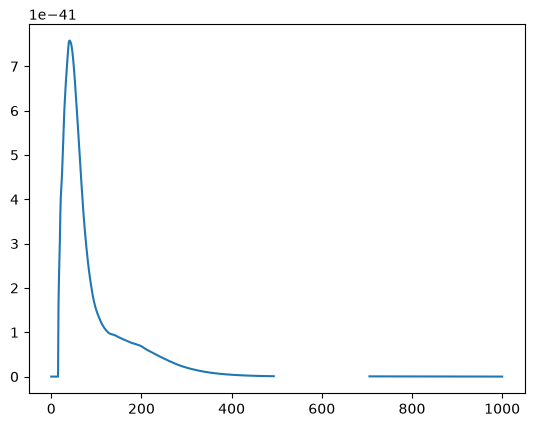

In [27]:
q = 200
ab_initio_q_index = np.argmin(np.abs(ab_initio_q - q))
eps = 600
omegavals = np.linspace(0, 1000, 1000)
ab_initio_curves = []
for i in range(5):
    ab_initio_curve = ab_initio_values[ab_initio_q_index, i, 1, :]
    ab_initio_curves.append(np.interp(omegavals, ab_initio_values[ab_initio_q_index, i, 0, :], ab_initio_curve))
ab_initio_curves = np.array(ab_initio_curves)
print(ab_initio_curves.shape)
ab_initio_xsec = plot_xsec(eps, q, omegavals, ab_initio_curves)

plt.plot(omegavals, ab_initio_xsec, label="Ab Initio")